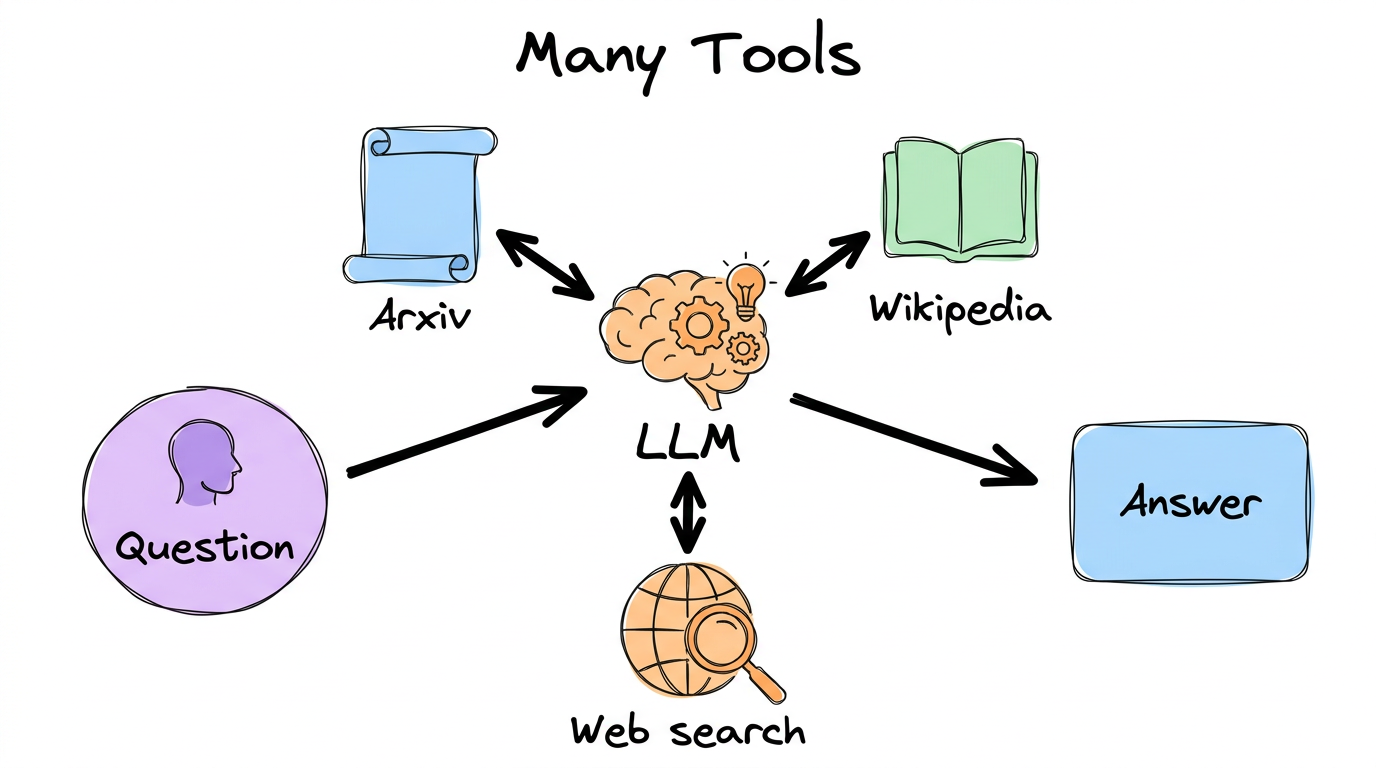

### Building Chatbot With Multiple Tools Using Langgraph
#### Aim
Create a chatbot with tool capabilities from arxiv, wikipedia search and some functions

In [1]:
from dotenv import load_dotenv
load_dotenv()  

True

In [2]:
import re
import arxiv
from langchain_core.tools import tool

arxiv_client = arxiv.Client(page_size=2, delay_seconds=5, num_retries=5)

@tool
def arxiv_search(query: str) -> str:
    """Search arXiv for research papers. Accepts keywords, a title, or an arXiv id such as 1706.03762."""
    if re.fullmatch(r"\d{4}\.\d{4,5}", query.strip()):
        search = arxiv.Search(id_list=[query.strip()])
    else:
        search = arxiv.Search(query=query, max_results=2)
    papers = arxiv_client.results(search)
    return "\n\n".join(f"Title: {p.title}\nPublished: {p.published.date()}\nSummary: {p.summary[:500]}" for p in papers)

print(arxiv_search.name)

arxiv_search


In [3]:
arxiv_search.invoke("1706.03762")

'Title: Attention Is All You Need\nPublished: 2017-06-12\nSummary: The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more '

In [5]:
import wikipedia

wikipedia.set_user_agent("langgraph-teaching-notebooks/1.0 (educational)")

@tool
def wikipedia_search(query: str) -> str:
    """Look up a topic on Wikipedia and return a short summary."""
    titles = wikipedia.search(query, results=1)
    if not titles:
        return "No Wikipedia page found."
    try:
        return wikipedia.summary(titles[0], sentences=4, auto_suggest=False)
    except wikipedia.DisambiguationError as e:
        return wikipedia.summary(e.options[0], sentences=4, auto_suggest=False)

wikipedia_search.name

'wikipedia_search'

In [6]:
wikipedia_search.invoke("What is machine learning")

'Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.\nStatistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.\nFrom a theoretical viewpoint, probably approximately correct learning provides a mathematical and statistical framework for describing machine learning.'

In [9]:
from langchain_openai import AzureChatOpenAI

search_llm = AzureChatOpenAI(
    azure_deployment="gpt-4.1-mini",
    temperature=0,
    api_version="2024-12-01-preview"
)
@tool
def web_search(query: str) -> str:
    """Search the web for recent or real-time information such as news."""
    return search_llm.invoke(query).text

In [10]:
web_search.invoke("Give me two recent AI news headlines")

'Sure! Here are two recent AI news headlines:\n\n1. "OpenAI Releases GPT-4 Turbo, Offering Faster and Cheaper Access to Advanced Language Models"\n2. "Google Unveils Bard AI Updates with Enhanced Multimodal Capabilities and Real-Time Data Integration"\n\nIf you\'d like more details on either, just let me know!'

In [11]:
tools=[arxiv_search,wikipedia_search,web_search]

In [12]:
llm = AzureChatOpenAI(
    azure_deployment="gpt-4.1-mini",
    temperature=0,
    api_version="2024-12-01-preview"
)

llm_with_tools=llm.bind_tools(tools)

In [13]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")])

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 16, 'prompt_tokens': 127, 'total_tokens': 143, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 12, 'engine_ttft_ms': 36, 'engine_ttlt_ms': 248, 'pre_inference_ms': 100, 'service_tbt_ms': 13, 'service_ttft_ms': 604, 'service_ttlt_ms': 807, 'user_visible_ttft_ms': 504}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_36de3d5958', 'id': 'chatcmpl-EmJ4nUO1oV6DqyJkr5fhRdErv2faB', 'service_tier': 'default', 'prompt_filter_results': [{'prompt_index': 0, 'content_filter_results': {'hate': {'filtered': False, 'severity': 'safe'}, 'jailbreak': {'detected': False, 'filtered': False}, 'self_harm': {'filtered': False,

In [14]:
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls

[{'name': 'web_search',
  'args': {'query': 'recent AI news'},
  'id': 'call_szm5YNUNwFlhurkcc1iT3juU',
  'type': 'tool_call'}]

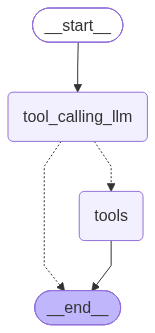

In [15]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools", END)


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
messages=graph.invoke({"messages":HumanMessage(content="1706.03762")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

1706.03762
================================== Ai Message ==================================
Tool Calls:
  arxiv_search (call_sFTmdPB6Vuj3QS8u11VoLYxb)
 Call ID: call_sFTmdPB6Vuj3QS8u11VoLYxb
  Args:
    query: 1706.03762
================================= Tool Message =================================
Name: arxiv_search

Title: Attention Is All You Need
Published: 2017-06-12
Summary: The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more 


In [17]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news
================================== Ai Message ==================================
Tool Calls:
  web_search (call_KEBVImOISEfIwOhCJlV5jFmT)
 Call ID: call_KEBVImOISEfIwOhCJlV5jFmT
  Args:
    query: recent AI news
================================= Tool Message =================================
Name: web_search

As of June 2024, here are some of the recent notable developments in AI:

1. **OpenAI's GPT-4 Turbo Release**  
   OpenAI has launched GPT-4 Turbo, a more efficient and cost-effective version of GPT-4. It powers ChatGPT Plus and Enterprise plans, offering faster responses and improved performance.

2. **Google DeepMind's Gemini AI**  
   Google DeepMind introduced Gemini, a next-generation AI model designed to compete with GPT-4. Gemini integrates advanced reasoning and multimodal capabilities, combining text, images, and other data types.

3. **AI Regulation Adva

In [18]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================
Tool Calls:
  wikipedia_search (call_5b5OtQAzJF3Lnk0LrjpMryVj)
 Call ID: call_5b5OtQAzJF3Lnk0LrjpMryVj
  Args:
    query: Machine learning
================================= Tool Message =================================
Name: wikipedia_search

Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.
Statistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.
From a theoretical viewpoint, probably approximately correct learning provides a mathematical and statist